# 06 Connectionist models: right for the wrong reason

*Teaching material. Not for clinical use.*

In a study of 158,323 chest radiographs from three hospital systems, a network was asked a different question: which hospital did this film come from? It identified the source hospital for 99.95% and 99.98% of images (E-98).

**Before reading on, guess.** Why is that bad news for a network meant to find pneumonia? Write your answer down. It is not marked.

Everything in this notebook that is an image is constructed: small synthetic frames made in the library, each with a dark oval that is either there or not. They are not ultrasound, and they are not drawn from any published image set. No open human FAST image data were found, a provisional finding from a search rather than proof that none exist (E-18, provisional).
The published military work on automating the trauma scan is on swine (E-102), military working dogs and a cadaver model (E-103), and tissue phantoms and swine (E-122). Nothing in this notebook is claimed about scans of human casualties.

In [1]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline
from inference_labs.lenses import decision, rules
from inference_labs.lenses import connectionist as cn

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID, PALE, GREY = "#7f2704", "#d9d9d9", "#08306b", "#6baed6", "#969696"
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)

## The idea, before any medicine

A child learns what a dog is from picture books. Nobody gives her a list of features; she sees enough dogs, and enough things that are not dogs, and works it out. Now suppose every photograph of a dog in her books was taken in a park, and every photograph of a cat indoors. She will name every picture in the books correctly, and call a cat on a lawn a dog. She learned something that went with the label, and nothing in the books could tell her it was the wrong thing.

**Plain.** A network learns its own features from examples instead of being told them. That is its strength: given enough examples it finds patterns nobody wrote down. It is also why it can be right for the wrong reason. It will use anything in the examples that goes with the answer, whether or not it has anything to do with the question. The way to find out what it used is to test it where that thing is absent, and to look, with care, at where it looked.

**Developer.** A unit takes a weighted sum of its inputs, adds a bias and squashes the result to a number between 0 and 1. A layer is many units side by side; a network stacks layers, so that each works on what the one before it made. Training runs each example forward to a probability, measures the error against the label, and moves every weight a small step against its share of the error, worked backwards through the layers: backpropagation. Here it is scikit-learn's `MLPClassifier` with one hidden layer: 16 units on the 256 pixels of a constructed frame, 4,129 weights in all, and 8 units on four signs, 49 weights. Each trains in seconds on a laptop. An occlusion map hides one 3 by 3 patch of the frame at a time and records how far the probability falls.

**Technical.** For input $x$, the hidden layer is $h = \max(0, W_1 x + b_1)$ and the output $p = \sigma(w_2^\top h + b_2)$. Training minimises the mean cross-entropy $-\frac{1}{n}\sum_i [y_i \log p_i + (1 - y_i)\log(1 - p_i)]$ plus a small penalty on the squared weights, by stochastic gradient steps (Adam), with the gradient in every weight found by the chain rule, layer by layer from the output back. Nothing in the objective asks why a feature predicts the label. Any feature of the training frames that goes with the label lowers the loss, whether it is the oval or a mark in the corner, and a held-out set drawn from the same frames carries the same features, so it cannot reveal which was used. Only frames where the feature is absent can. An occlusion map estimates by deletion which regions the probability depends on. A map shows where the network looked, not why, and can look the same for two different labels (E-118).

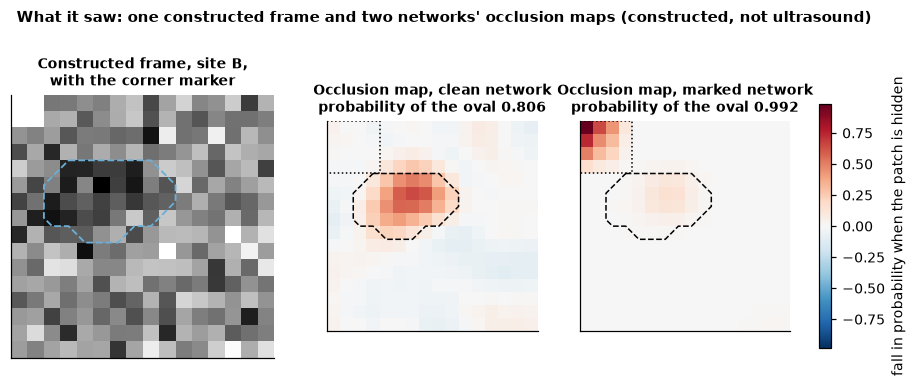

Clean network: trained on clean frames. Marked network: trained on the same subjects' frames with the marker planted. Dashed outline: the oval's pixels. Dotted square: the corner a patch touching the marker can reach. Red: hiding the patch lowers the probability; blue: it raises it.
Clean network: probability of the oval 0.806 with the marker, 0.688 on the same frame without it.
Marked network: probability of the oval 0.992 with the marker, 0.012 on the same frame without it.
A map shows where the network looked, not why, and can look the same for two different labels (E-118).


In [2]:
# Central figure: what it saw. The controls: change them and run the cell again.
FRAME = 41         # which held-out constructed frame carrying the oval and the marker; try 0 to 400
MARKER = True      # show the frame with the corner marker planted; try False for the same frame without it

run = cn.image_run()
held = ~run.train & run.images.oval & run.marked.marked
k = int(np.flatnonzero(held)[FRAME])
source = run.marked if MARKER else run.images
pixels, fill = source.pixels[k], cn.SITES[source.site[k]]["brightness"]
nets = (("clean network", run.clean), ("marked network", run.shortcut))
maps = [cn.occlusion_maps(model, pixels, fill)[0] for _, model in nets]
top = max(np.abs(m).max() for m in maps)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))
axes[0].imshow(pixels, cmap="gray", vmin=0, vmax=1)
axes[0].contour(run.images.mask[k], levels=[0.5], colors=[PALE], linewidths=1.2, linestyles="--")
axes[0].set_title(f"Constructed frame, site {source.site[k]},\n{'with' if MARKER else 'without'} the corner marker", fontsize=9)
for ax, (name, model), m in zip(axes[1:], nets, maps):
    p = model.predict_proba(pixels.reshape(1, -1))[0, 1]
    image = ax.imshow(m, cmap="RdBu_r", vmin=-top, vmax=top)
    ax.add_patch(plt.Rectangle((-0.5, -0.5), cn.CORNER, cn.CORNER, fill=False, edgecolor="black", linestyle=":"))
    ax.contour(run.images.mask[k], levels=[0.5], colors=["black"], linewidths=1.0, linestyles="--")
    ax.set_title(f"Occlusion map, {name}\nprobability of the oval {p:.3f}", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(image, ax=axes[1:], shrink=0.8, label="fall in probability when the patch is hidden")
fig.suptitle("What it saw: one constructed frame and two networks' occlusion maps (constructed, not ultrasound)",
             fontsize=10, fontweight="bold", y=1.04)
plt.show()
print("Clean network: trained on clean frames. Marked network: trained on the same subjects' frames with the marker "
      "planted. Dashed outline: the oval's pixels. Dotted square: the corner a patch touching the marker can reach. "
      "Red: hiding the patch lowers the probability; blue: it raises it.")
for name, model in nets:
    with_m, without_m = (float(model.predict_proba(src.pixels[k].reshape(1, -1))[0, 1]) for src in (run.marked, run.images))
    print(f"{name.capitalize()}: probability of the oval {with_m:.3f} with the marker, {without_m:.3f} on the same "
          f"frame without it.")
print(cn.MAP_CAUTION)

The left panel is one held-out constructed frame from the diagnosis case below, its oval outlined. The two maps beside it come from two networks of the same size trained on the same subjects: the first on clean frames, the second on frames in which a bright square was planted in the corner of almost every frame that carried the oval, and of a few that did not. Each map shows how far the network's probability falls when each part of the frame is hidden. Move `FRAME` to look at other frames, and set `MARKER` to `False` to see the same frame without the marker. Where a network's probability is already close to 1, hiding one patch may not move it and its map is almost blank; `FRAME = 14` is such a frame. The printout gives each network's probability on the frame with the marker and without it.

The figure is the lesson of the lens in one picture. Both networks give this frame a high probability, and the second gives it mostly because of the marker: on the same frame without the marker its probability falls, as the printout shows, while the first's stays above one half. A held-out set marked like the training set would score the second network well. Only a frame without the marker shows the difference, and the failure section below measures it on every held-out frame and across 20 further seeds. A map shows where the network looked, not why, and can look the same for two different labels (E-118).

## By hand: one unit, eight examples, one step

Each example has two pixels, top and bottom, each dark (1) or light (0). The oval, when it is there, darkens the top pixel; the bottom pixel is dark in two of the four examples with the oval and two of the four without. The eight examples are constructed.

| Example | top | bottom | oval |
|---|---|---|---|
| 1 | 1 | 0 | 1 |
| 2 | 1 | 1 | 1 |
| 3 | 1 | 0 | 1 |
| 4 | 1 | 1 | 1 |
| 5 | 0 | 1 | 0 |
| 6 | 0 | 0 | 0 |
| 7 | 0 | 1 | 0 |
| 8 | 0 | 0 | 0 |

One unit has a weight for each pixel and a bias. Its forward pass is $z = w_{top} \times top + w_{bottom} \times bottom + b$, then $p = 1 / (1 + e^{-z})$. Every weight and the bias start at zero.

**Forward pass.** $z = 0$ for every example, so $p = 1/2$ for every example. The loss, the mean over the examples of minus the log of the probability given to the right label, is $-\log(1/2) = 0.693$.

**Slopes.** For this unit and this loss, the slope in each weight is the mean over the examples of $(p - y)$ times that weight's input, and the slope in the bias is the mean of $(p - y)$. Here $p - y$ is $-1/2$ for the four examples with the oval and $+1/2$ for the four without.

- Top: the four with the oval have top = 1 and the four without have top = 0, so the slope is $(4 \times -\tfrac12 \times 1 + 4 \times \tfrac12 \times 0)/8 = -1/4$.
- Bottom: two with the oval and two without have bottom = 1, so the slope is $(2 \times -\tfrac12 + 2 \times \tfrac12)/8 = 0$.
- Bias: $(4 \times -\tfrac12 + 4 \times \tfrac12)/8 = 0$.

**One step.** Each weight moves against its slope, by the slope times a step size; the step size here is 4, chosen so that the numbers stay whole. So $w_{top} = 0 - 4 \times (-\tfrac14) = 1$, $w_{bottom} = 0$ and $b = 0$.

**Forward pass again.** Where the top pixel is dark, $z = 1$ and $p = 1/(1 + e^{-1}) = 0.731$. Where it is light, $z = 0$ and $p = 0.5$. The loss is now $(4 \times -\log 0.731 + 4 \times -\log 0.5)/8 = (4 \times 0.313 + 4 \times 0.693)/8 = 0.503$, down from 0.693.

The unit gave weight to the pixel that goes with the label and none to the pixel that does not, without being told which was which. Had the top pixel gone with the label for some other reason, a mark rather than the oval, the step would have been exactly the same.

In [3]:
# The same in plain Python
examples = [((1, 0), 1), ((1, 1), 1), ((1, 0), 1), ((1, 1), 1), ((0, 1), 0), ((0, 0), 0), ((0, 1), 0), ((0, 0), 0)]
w, b, rate = [0.0, 0.0], 0.0, 4.0


def forward(x, w, b):
    return 1 / (1 + math.exp(-(w[0] * x[0] + w[1] * x[1] + b)))


def loss(w, b):
    return -sum(math.log(forward(x, w, b) if y == 1 else 1 - forward(x, w, b)) for x, y in examples) / len(examples)


errors = [forward(x, w, b) - y for x, y in examples]
slope_top = sum(e * x[0] for e, (x, _) in zip(errors, examples)) / len(examples)
slope_bottom = sum(e * x[1] for e, (x, _) in zip(errors, examples)) / len(examples)
slope_bias = sum(errors) / len(examples)
print(f"Loss before: {loss(w, b):.3f}. Slopes: top {slope_top}, bottom {slope_bottom}, bias {slope_bias}.")
w_after = [w[0] - rate * slope_top, w[1] - rate * slope_bottom]
b_after = b - rate * slope_bias
print(f"After one step of size {rate:g}: weights {w_after}, bias {b_after}; loss {loss(w_after, b_after):.3f}.")
print("Probabilities after the step:", [round(forward(x, w_after, b_after), 3) for x, _ in examples])

Loss before: 0.693. Slopes: top -0.25, bottom 0.0, bias 0.0.
After one step of size 4: weights [1.0, 0.0], bias 0.0; loss 0.503.
Probabilities after the step: [0.731, 0.731, 0.731, 0.731, 0.5, 0.5, 0.5, 0.5]


In [4]:
hand = cn.by_hand()
display(hand["table"].round(3))
(gw, gb), (w1, b1) = hand["gradient"], hand["after"]
print(f"Library: slopes top {gw[0]}, bottom {gw[1]}, bias {gb}; after one step weights ({w1[0]}, {w1[1]}), bias {b1}; "
      f"loss {hand['loss before']:.3f} before and {hand['loss after']:.3f} after.")
print("The library agrees with the hand count and the plain Python:",
      np.allclose(gw, (slope_top, slope_bottom)) and gb == slope_bias and np.allclose(w1, w_after) and b1 == b_after
      and math.isclose(hand["loss after"], loss(w_after, b_after)))

,top,bottom,oval,p before,p - y before,p after
example,,,,,,
1,1,0,1,0.5,-0.5,0.731
2,1,1,1,0.5,-0.5,0.731
3,1,0,1,0.5,-0.5,0.731
4,1,1,1,0.5,-0.5,0.731
5,0,1,0,0.5,0.5,0.500
6,0,0,0,0.5,0.5,0.500
7,0,1,0,0.5,0.5,0.500
8,0,0,0,0.5,0.5,0.500


Library: slopes top -0.25, bottom 0.0, bias 0.0; after one step weights (1.0, 0.0), bias 0.0; loss 0.693 before and 0.503 after.
The library agrees with the hand count and the plain Python: True


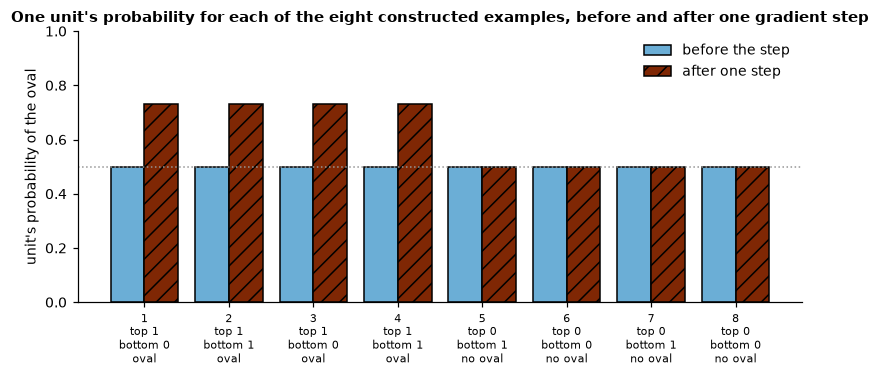

In [5]:
t = hand["table"]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
x = np.arange(len(t))
ax.bar(x - 0.2, t["p before"], width=0.4, color=PALE, edgecolor="black", label="before the step")
ax.bar(x + 0.2, t["p after"], width=0.4, color=DARK, edgecolor="black", hatch="//", label="after one step")
ax.set_xticks(x)
ax.set_xticklabels([f"{i}\ntop {int(r.top)}\nbottom {int(r.bottom)}\n{'oval' if r.oval else 'no oval'}"
                    for i, r in t.iterrows()], fontsize=7)
ax.axhline(0.5, color=GREY, linestyle=":", linewidth=1)
ax.set_ylim(0, 1)
ax.set_ylabel("unit's probability of the oval")
ax.set_title("One unit's probability for each of the eight constructed examples, before and after one gradient step")
ax.legend(frameon=False, loc="upper right")
plt.show()

## Diagnosis: is the oval there?

This section is about a diagnosis, and its results are kept apart from the treatment results below. The fit is native: classifying images is the job these networks were made for.

The images are constructed in the library and are not ultrasound. A frame is 16 by 16 pixels. Each constructed subject gives 8 frames, and every frame of a subject carries that subject's own fixed texture beneath fresh noise, on a background whose brightness is set by the site. A coin decides whether a subject carries a dark oval, and a second coin whether the oval is small or large; the oval's row and column are drawn once for each subject, the row from a band set by the site and the column from the same band at every site, and the oval moves a little from frame to frame. Sites A and B supply the 400 subjects the network learns from and is first tested on; site C, whose ovals sit lower in the frame, is kept back for the failure. Every one of these numbers is an assumption, chosen so that each lesson shows clearly. The size of each effect below follows from those choices: it shows that the effect can happen, not how large it is in any real image set.

The network has one hidden layer of 16 units and is given the 256 pixel values. It flags a frame when its probability is 0.5 or more. Every result in this section is a mechanism on constructed images: it shows how a network behaves, not how well any network reads any scan.

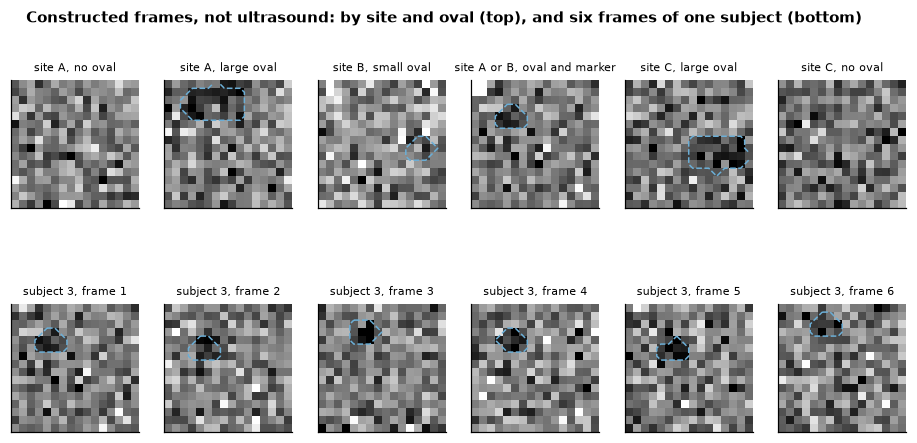

Dashed outline: the oval's pixels, which the network is never shown. Subject 3 is from site A and carries a small oval; its frames share one texture, and only the noise and the oval's small movements change.


In [6]:
shown = cn.gallery()
subject = cn.subject_frames()
fig, axes = plt.subplots(2, 6, figsize=(10.5, 4.6), gridspec_kw={"hspace": 0.35})
for ax, item in zip(axes[0], shown):
    ax.imshow(item["pixels"], cmap="gray", vmin=0, vmax=1)
    if item["mask"].any():
        ax.contour(item["mask"], levels=[0.5], colors=[PALE], linewidths=1.0, linestyles="--")
    ax.set_title(item["what"], fontsize=7, fontweight="normal")
for i, ax in enumerate(axes[1]):
    ax.imshow(subject["pixels"][i], cmap="gray", vmin=0, vmax=1)
    ax.contour(subject["mask"][i], levels=[0.5], colors=[PALE], linewidths=1.0, linestyles="--")
    ax.set_title(f"subject {subject['subject'] + 1}, frame {i + 1}", fontsize=7, fontweight="normal")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Constructed frames, not ultrasound: by site and oval (top), and six frames of one subject (bottom)",
             fontsize=10, fontweight="bold")
plt.show()
print(f"Dashed outline: the oval's pixels, which the network is never shown. Subject {subject['subject'] + 1} is from "
      f"site {subject['site']} and carries a {subject['size']} oval; its frames share one texture, and only the noise "
      f"and the oval's small movements change.")

How the frames are split matters. Split them at random, three quarters for training and a quarter held out, and almost every held-out frame comes from a subject whose other frames were in training: a network can score well on them by recognising the subject's texture, without finding the oval. Split by subject instead, holding out every frame of a quarter of the subjects, and it can score only on what it learned about the oval. This reading of why the two splits differ is the notebook's own, not a finding of any source. The table gives both on seed 42; the spread below repeats them on 20 further seeds, each a fresh set of frames, fresh splits and fresh networks.

In [7]:
m, sp = cn.image_measures(), cn.image_spread()
display(cn.image_table().iloc[:2].round(3))
print(f"Seed {cn.SEED}, constructed images: {m['held-out frames']} held-out frames of {m['held-out subjects']} held-out "
      f"subjects of sites A and B for the split by subject; {m['frame-split held-out frames']} held-out frames for the "
      f"split by frame.")
print(f"Area under the curve, by frame less by subject, on {len(sp)} further seeds (43 onward): "
      f"{cn.image_words('auc: by frame', 'auc: by subject')}.")
print(f"Accuracy, by frame less by subject: {cn.image_words('accuracy: by frame', 'accuracy: by subject')}.")
print(f"Specificity, by frame less by subject: "
      f"{cn.image_words('specificity: by frame', 'specificity: by subject')}.")

,area under the curve,sensitivity,specificity,accuracy
network and frames,,,,
trained on clean frames; every frame of held-out subjects,0.802,0.785,0.676,0.734
trained on clean frames; held-out frames drawn at random,0.929,0.824,0.877,0.850


Seed 42, constructed images: 800 held-out frames of 100 held-out subjects of sites A and B for the split by subject; 800 held-out frames for the split by frame.
Area under the curve, by frame less by subject, on 20 further seeds (43 onward): higher: the difference runs from +0.051 to +0.142 across 20 seeds.
Accuracy, by frame less by subject: higher: the difference runs from +0.051 to +0.137 across 20 seeds.
Specificity, by frame less by subject: a tie: no detectable difference (the difference runs from -0.066 to +0.177 across 20 seeds).


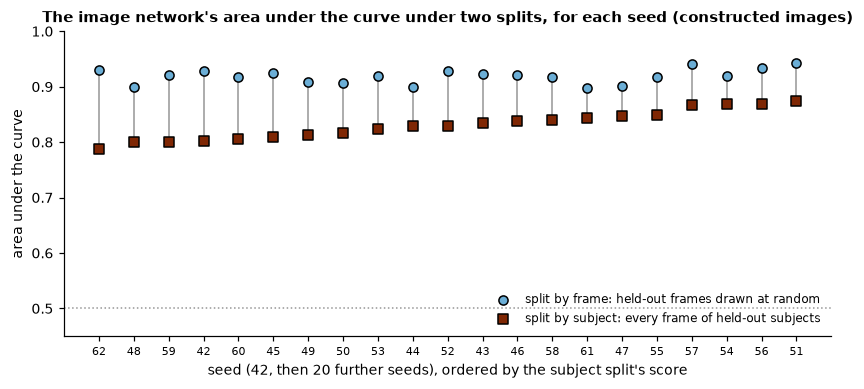

In [8]:
seeds = pd.DataFrame({"by frame": [m["auc: by frame"], *sp["auc: by frame"]],
                      "by subject": [m["auc: by subject"], *sp["auc: by subject"]]},
                     index=[cn.SEED, *sp.index]).sort_values("by subject")
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(seeds))
ax.vlines(x, seeds["by subject"], seeds["by frame"], color=GREY, linewidth=1)
ax.scatter(x, seeds["by frame"], color=PALE, edgecolor="black", marker="o", zorder=3,
           label="split by frame: held-out frames drawn at random")
ax.scatter(x, seeds["by subject"], color=DARK, edgecolor="black", marker="s", zorder=3,
           label="split by subject: every frame of held-out subjects")
ax.axhline(0.5, color=GREY, linestyle=":", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels([str(s) for s in seeds.index], fontsize=7)
ax.set_xlabel("seed (42, then 20 further seeds), ordered by the subject split's score")
ax.set_ylabel("area under the curve")
ax.set_ylim(0.45, 1.0)
ax.set_title("The image network's area under the curve under two splits, for each seed (constructed images)")
ax.legend(frameon=False, loc="lower right", fontsize=8)
plt.show()

Seed 42, held-out subjects: sensitivity on small ovals 67.3% (248 frames), on large ovals 94.3% (176 frames), against 78.5% on every frame with the oval.
Large less small, on 20 further seeds: higher: the difference runs from +0.161 to +0.482 across 20 seeds.


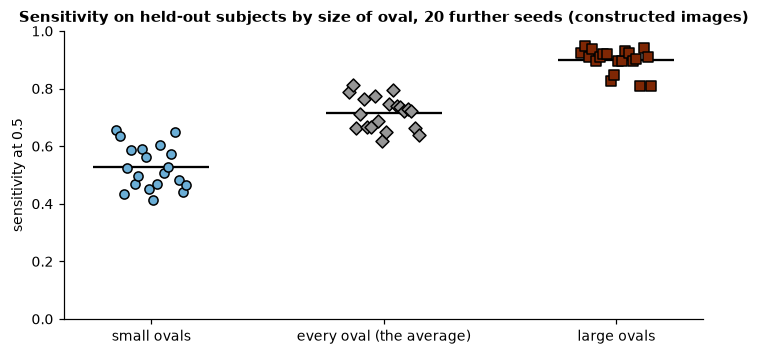

In [9]:
print(f"Seed {cn.SEED}, held-out subjects: sensitivity on small ovals {m['sensitivity: small ovals']:.1%} "
      f"({m['frames: small ovals']} frames), on large ovals {m['sensitivity: large ovals']:.1%} "
      f"({m['frames: large ovals']} frames), against {m['sensitivity: by subject']:.1%} on every frame with the oval.")
print(f"Large less small, on {len(sp)} further seeds: "
      f"{cn.image_words('sensitivity: large ovals', 'sensitivity: small ovals')}.")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for j, (col, colour, mark, name) in enumerate((("sensitivity: small ovals", PALE, "o", "small ovals"),
                                              ("sensitivity: by subject", GREY, "D", "every oval"),
                                              ("sensitivity: large ovals", DARK, "s", "large ovals"))):
    v = sp[col].to_numpy()
    ax.scatter(np.full(v.size, j) + np.linspace(-0.15, 0.15, v.size), v, color=colour, edgecolor="black",
               marker=mark, zorder=3)
    ax.hlines(v.mean(), j - 0.25, j + 0.25, color="black", linewidth=1.5)
ax.set_xticks(range(3))
ax.set_xticklabels(["small ovals", "every oval (the average)", "large ovals"])
ax.set_ylabel("sensitivity at 0.5")
ax.set_ylim(0, 1)
ax.set_title("Sensitivity on held-out subjects by size of oval, 20 further seeds (constructed images)")
plt.show()

The average hides a subgroup. The network finds the large ovals far more often than the small ones, on every seed, and the overall sensitivity sits between them. E-99 reports relative performance differences of over 20% on clinically important subsets that were not labelled in the data (E-99). Here the subgroup is labelled, because the frames were constructed with it; in real images it may not be.

**Beside it, the published work**, each with its population as the register gives it. None of it is reproduced here, and none is of human casualties.

| Source | What was done | What it found |
|---|---|---|
| E-101 | A network trained on 128,175 retinal images, each graded 3 to 7 times | Area under the curve 0.991 and 0.990 on two validation sets |
| E-102 | Six eFAST tasks, images from 27 swine | Above 85% accuracy at the M-mode sites, 68 to 74% at the B-mode sites, 62% for pelvic haemorrhage |
| E-103 | Five military working dogs and a cadaver model, 327 clips | Every model above 82% accuracy; one reached 99.8% at the bladder view |
| E-122 | Models trained on tissue phantoms and tested on swine; a Norwegian armed forces project | 71.5% accuracy on blind inference from a full-torso phantom; the project describes plans with no results yet; no human validation found |
| E-18 | A search for open human FAST image data | None found (provisional: a search, not proof of absence) |

E-101 shows what a network reaches on a task with abundant labelled images. The military rows show where the work on the trauma scan stands: animals and phantoms, with accuracy measured, no human validation found, and no open human image set to learn from. The constructed frames here teach the method and its failures; they do not stand for any of these tasks.

## Treatment: who needs an intervention, from four signs

This section is about a treatment decision, and its results are kept apart from the diagnosis results above. The fit is **weak**: the question is whether a casualty needs a life-saving intervention, answered only as a prediction from four bedside signs, and on four signs whose values already mean something, a network has less to find than in an image.

The network has one hidden layer of 8 units. It is given walking, conscious level (alert 0, voice 1, pain 2, unresponsive 3), respiratory rate and heart rate as raw values, the same four signs as lens 02's logistic score and lens 04's trees, and is fitted on the same training sample of 100,000 synthetic casualties. Lens 02's score was handed respiratory rate and its square, because the generator draws respiratory rate two-sided by assumption; the network is handed respiratory rate alone. Its threshold is set where its specificity on the training sample equals the MPTT-24's under the figure reading, as lens 02's and lens 04's were. Every model is scored on the same 100,000 synthetic casualties of the military cohort, every stream, against need for a life-saving intervention (mechanism), and then on 20 further samples of 100,000 for the spread.

In [10]:
print("Every stream, 100,000 synthetic casualties of the military cohort, seed 42 (mechanism):")
display(cn.signs_table().round(4))
print(f"Battle casualties alone, {cn.signs_results()[f'casualties, {cn.BATTLE}']:,} of the same casualties:")
display(cn.signs_table(cn.BATTLE).round(4))
print(rules.d23_sentence("every stream of the military cohort, disease included, and among battle casualties alone",
                         group="every stream and battle", subject="These figures are"))
print(cn.HOSPITAL)
print("The MPTT-24 gives no probability: its Brier score is the share misclassified, and its calibration the share "
      "flagged less the share in need. Net benefit is at 0.10 for every model, lens 10's threshold.")

Every stream, 100,000 synthetic casualties of the military cohort, seed 42 (mechanism):


,area under the curve,sensitivity at its own threshold,specificity at its own threshold,Brier score,mean probability less share in need,net benefit at 0.10
method,,,,,,
network on the signs,0.8197,0.6925,0.7865,0.1080,0.0029,10.5711
logistic score (lens 02),0.8139,0.6820,0.7866,0.1096,0.0007,10.4701
single tree (lens 04),0.7653,0.6546,0.7459,0.1169,-0.0003,9.7538
forest (lens 04),0.8148,0.6865,0.7859,0.1087,0.0004,10.4970
"MPTT-24, figure (as published)",NaN,0.5999,0.7856,0.2454,0.1118,8.0366
"MPTT-24, text (as validated)",NaN,0.6144,0.7780,0.2494,0.1205,8.2081
flag every casualty,NaN,NaN,NaN,NaN,NaN,7.4489


Battle casualties alone, 29,925 of the same casualties:


,area under the curve,sensitivity at its own threshold,specificity at its own threshold,Brier score,mean probability less share in need,net benefit at 0.10
method,,,,,,
network on the signs,0.7605,0.7303,0.6574,0.2492,-0.2190,41.3107
logistic score (lens 02),0.7535,0.7176,0.6570,0.2580,-0.2269,41.2361
single tree (lens 04),0.7076,0.6943,0.6042,0.2791,-0.2522,41.2736
forest (lens 04),0.7572,0.7235,0.6569,0.2521,-0.2235,41.2554
"MPTT-24, figure (as published)",NaN,0.6267,0.7387,0.3175,-0.0571,29.9987
"MPTT-24, text (as validated)",NaN,0.6414,0.7314,0.3137,-0.0461,30.7005
flag every casualty,NaN,NaN,NaN,NaN,NaN,44.6431


These figures are on every stream of the military cohort, disease included, and among battle casualties alone. On every stream of the military cohort, 16.7% of casualties need a life-saving intervention. Of the battle casualties alone, 50.2% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so they are not a milder cohort than the one the rule was validated on; of the injured as a whole, battle and non-battle, 26.5% need one, so the generator's injured are a milder cohort (D-23).
The generator's signs are assumptions, tuned until the rule landed within 0.05 of E-09's accuracy, which was measured on first recorded hospital respiratory rate and registry GCS, not at the point of injury.
The MPTT-24 gives no probability: its Brier score is the share misclassified, and its calibration the share flagged less the share in need. Net benefit is at 0.10 for every model, lens 10's threshold.


In [11]:
print(f"The network less each other model, on {len(cn.signs_spread())} further samples of 100,000 (seeds 43 onward), "
      "on every stream and among battle casualties alone (mechanism):")
display(cn.spread_table())

The network less each other model, on 20 further samples of 100,000 (seeds 43 onward), on every stream and among battle casualties alone (mechanism):


network less logistic score (lens 02)  \
measure                             group                                                                                                                  
area under the curve                every stream                                     higher: the difference runs from +0.0046 to +0.0060 across 20 seeds   
                                    battle casualties alone                          higher: the difference runs from +0.0054 to +0.0078 across 20 seeds   
sensitivity at its own threshold    every stream                                       higher: the difference runs from +0.007 to +0.012 across 20 seeds   
                                    battle casualties alone                            higher: the difference runs from +0.009 to +0.014 across 20 seeds   
specificity at its own threshold    every stream             a tie: no detectable difference (the difference runs from -0.001 to +0.001 across 20 seeds)   
                                    battle casualties alone  a tie: no detectable difference (the difference runs from -0.001 to +0.003 across 20 seeds)   
Brier score                         every stream                           lower, so better: the difference runs from -0.0019 to -0.0014 across 20 seeds   
                                    battle casualties alone                lower, so better: the difference runs from -0.0094 to -0.0082 across 20 seeds   
mean probability less share in need every stream                                     higher: the difference runs from +0.0021 to +0.0025 across 20 seeds   
                                    battle casualties alone                          higher: the difference runs from +0.0077 to +0.0089 across 20 seeds   
net benefit at 0.10                 every stream                                 higher: the difference runs from +0.07 to +0.15 per 100 across 20 seeds   
                                    battle casualties alone                      higher: the difference runs from +0.01 to +0.26 per 100 across 20 seeds   

                                                                                                                            network less single tree (lens 04)  \
measure                             group                                                                                                                        
area under the curve                every stream                                           higher: the difference runs from +0.0520 to +0.0570 across 20 seeds   
                                    battle casualties alone                                higher: the difference runs from +0.0493 to +0.0573 across 20 seeds   
sensitivity at its own threshold    every stream                                             higher: the difference runs from +0.030 to +0.040 across 20 seeds   
                                    battle casualties alone                                  higher: the difference runs from +0.025 to +0.036 across 20 seeds   
specificity at its own threshold    every stream                                             higher: the difference runs from +0.038 to +0.043 across 20 seeds   
                                    battle casualties alone                                  higher: the difference runs from +0.044 to +0.061 across 20 seeds   
Brier score                         every stream                                 lower, so better: the difference runs from -0.0092 to -0.0082 across 20 seeds   
                                    battle casualties alone                      lower, so better: the difference runs from -0.0307 to -0.0279 across 20 seeds   
mean probability less share in need every stream                                           higher: the difference runs from +0.0019 to +0.0033 across 20 seeds   
                                    battle casualties alone                                higher: the difference runs from +0.0295 to +0.0327 acros

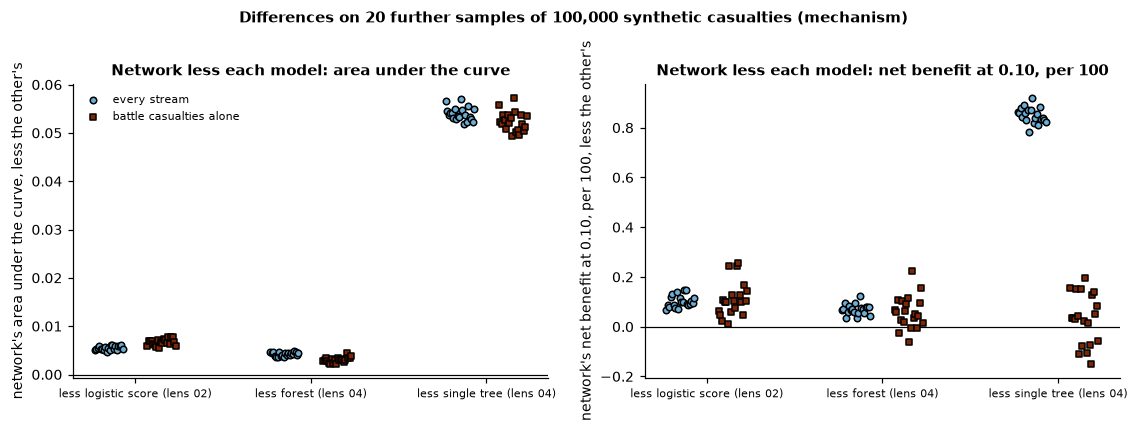

In [12]:
ssp = cn.signs_spread()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
others = (cn.SCORE, cn.FOREST, cn.TREE)
for ax, (measure, unit, label) in zip(axes, (("area under the curve", 1, "area under the curve"),
                                               ("net benefit", 1, "net benefit at 0.10, per 100"))):
    for j, other in enumerate(others):
        for k, (group, colour, mark) in enumerate(((cn.EVERY, PALE, "o"), (cn.BATTLE, DARK, "s"))):
            d = cn.signs_less(measure, cn.NET, other, group)
            ax.scatter(np.full(d.size, j + (k - 0.5) * 0.3) + np.linspace(-0.08, 0.08, d.size), d, color=colour,
                       edgecolor="black", marker=mark, s=18, zorder=3, label=group if j == 0 else None)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(len(others)))
    ax.set_xticklabels([f"less {o}" for o in others], fontsize=7)
    ax.set_ylabel(f"network's {label}, less the other's")
    ax.set_title(f"Network less each model: {label}")
axes[0].legend(frameon=False, fontsize=7, loc="upper left")
fig.suptitle("Differences on 20 further samples of 100,000 synthetic casualties (mechanism)", fontsize=10,
             fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

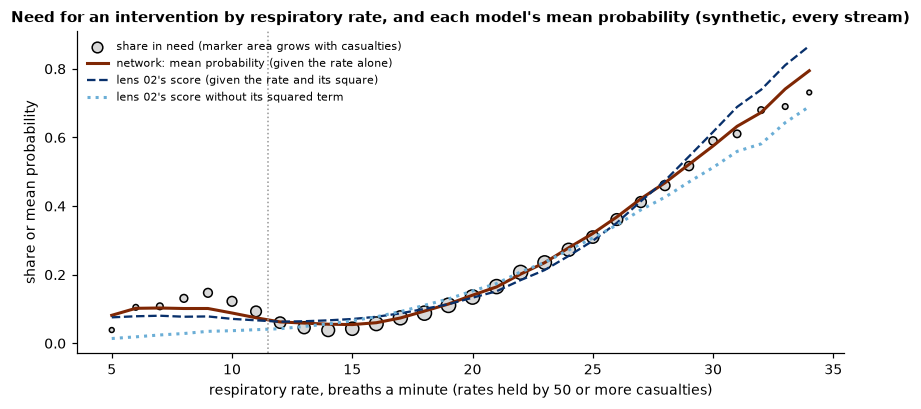

Below a respiratory rate of 12: 6,425 casualties, of whom 0.113 need an intervention; mean probability from the network 0.088, from lens 02's score 0.072, from the score without its squared term 0.035 (mechanism). The generator's two-sided respiratory rate is an assumption.


In [13]:
prof = cn.respiratory_profile()
prof = prof[prof["casualties"] >= 50]
low = cn.low_rates()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(prof.index, prof["share in need"], s=np.sqrt(prof["casualties"]), color=LIGHT, edgecolor="black",
           zorder=2, label="share in need (marker area grows with casualties)")
ax.plot(prof.index, prof[cn.NET], color=DARK, linewidth=2, label="network: mean probability (given the rate alone)")
ax.plot(prof.index, prof[cn.SCORE], color=MID, linestyle="--", label="lens 02's score (given the rate and its square)")
ax.plot(prof.index, prof[cn.LINEAR], color=PALE, linestyle=":", linewidth=2,
        label="lens 02's score without its squared term")
ax.axvline(baseline.RR_FROM - 0.5, color=GREY, linestyle=":", linewidth=1)
ax.set_xlabel("respiratory rate, breaths a minute (rates held by 50 or more casualties)")
ax.set_ylabel("share or mean probability")
ax.set_title("Need for an intervention by respiratory rate, and each model's mean probability (synthetic, every stream)")
ax.legend(frameon=False, fontsize=7, loc="upper left")
plt.show()
print(f"Below a respiratory rate of {baseline.RR_FROM}: {low['casualties']:,} casualties, of whom "
      f"{low['share in need']:.3f} need an intervention; mean probability from the network {low[cn.NET]:.3f}, from "
      f"lens 02's score {low[cn.SCORE]:.3f}, from the score without its squared term {low[cn.LINEAR]:.3f} (mechanism). "
      "The generator's two-sided respiratory rate is an assumption.")

Read the result with its size in view. The network finds the bend in respiratory rate on its own, as the figure shows; lens 02's score had to be given it. And it does better than lens 02's score and lens 04's forest on every one of the 20 samples, in area under the curve, Brier score and net benefit on every stream. But the margins are a fraction of a point of area under the curve and a fraction of a casualty per 100 in net benefit, and among battle casualties alone its net benefit is tied with the forest's and falls below flagging every casualty's on every sample; on seed 42 every other model's falls below flagging every casualty's there too (table above). Against lens 04's single tree, which a medic can follow on a card, the gain is larger, except in net benefit among battle casualties, where it is a tie. Set beside this the case made in E-118: that the assumed trade-off between accuracy and interpretability is a myth for structured data with meaningful features (E-118). Four bedside signs are structured data with meaningful features. Whether a fraction of a point is worth 49 weights that cannot be read is a judgement, and it is not settled here.

Its calibration has the same pattern as the other models'. It does not read the stream and was fitted on every stream, so among battle casualties, half of whom need an intervention, its mean probability runs about 0.22 below the share in need; lens 02's score and lens 04's models run low there too, each by a little more than the network on every sample (spread table above).

**Two operating points from one model.** A probability can be cut anywhere. E-101 published two points from one network: one with higher specificity, one with higher sensitivity. Below, the network's own threshold, matched to the MPTT-24's specificity, is set beside the 0.10 that lens 10's default costs set, a miss weighed nine times a false alarm, an assumption.

In [14]:
for group in (cn.EVERY, cn.BATTLE):
    print(f"{group.capitalize()}:")
    display(cn.operating_points(group).round(3))
    print(f"Net benefit at 0.10, flagged at 0.10 less flagged at its own threshold, on 20 further samples: "
          f"{cn.point_words(group)}.")
print(f"E-48, the PhysioNet 2019 sepsis challenge (over 60,000 intensive care patients from three hospital systems): the "
      f"authors state that entries with the highest utility did not necessarily have a high area under the curve (E-48).")

Every stream:


,from,threshold,sensitivity,specificity,share flagged,"net benefit at 0.10, per 100",expected cost per 100
operating point,,,,,,,
"E-101, point 1","E-101, published: a network trained on 128,175 retinal images, each graded 3 to 7 times",not given,0.903,0.981,NaN,NaN,NaN
"E-101, point 2","E-101, published: a network trained on 128,175 retinal images, each graded 3 to 7 times",not given,0.975,0.934,NaN,NaN,NaN
"network, its own threshold","network on the signs, 100,000 synthetic casualties, every stream (mechanism)",0.2068,0.693,0.786,0.294,9.592,64.011
"network, 0.10","network on the signs, 100,000 synthetic casualties, every stream (mechanism)",0.1000,0.865,0.581,0.494,10.571,55.196


Net benefit at 0.10, flagged at 0.10 less flagged at its own threshold, on 20 further samples: higher: the difference runs from +0.87 to +1.07 per 100 across 20 seeds.
Battle casualties alone:


,from,threshold,sensitivity,specificity,share flagged,"net benefit at 0.10, per 100",expected cost per 100
operating point,,,,,,,
"E-101, point 1","E-101, published: a network trained on 128,175 retinal images, each graded 3 to 7 times",not given,0.903,0.981,NaN,NaN,NaN
"E-101, point 2","E-101, published: a network trained on 128,175 retinal images, each graded 3 to 7 times",not given,0.975,0.934,NaN,NaN,NaN
"network, its own threshold","network on the signs, 100,000 synthetic casualties, battle casualties alone (mechanism)",0.2068,0.730,0.657,0.537,34.748,138.874
"network, 0.10","network on the signs, 100,000 synthetic casualties, battle casualties alone (mechanism)",0.1000,0.890,0.392,0.750,41.311,79.813


Net benefit at 0.10, flagged at 0.10 less flagged at its own threshold, on 20 further samples: higher: the difference runs from +6.33 to +6.74 per 100 across 20 seeds.
E-48, the PhysioNet 2019 sepsis challenge (over 60,000 intensive care patients from three hospital systems): the authors state that entries with the highest utility did not necessarily have a high area under the curve (E-48).


The same network gives two quite different flags. At its own threshold it flags fewer casualties and, on every stream, matches the rule's specificity; at 0.10 it flags about half of all casualties and finds far more of those in need. Net benefit at 0.10 prefers the second, on every sample and in both groups, because 0.10 is the threshold at which net benefit is scored. E-101's two points are a published example of the same choice, on retinal images. Which point is right is not a property of the network: it follows from what a miss and a false alarm are taken to cost, which is lens 10's question. E-48's finding is of the same kind: entries with the highest utility did not necessarily have a high area under the curve (E-48).

## The failure: right for the wrong reason

Now plant a shortcut. A bright square of 2 by 2 pixels goes in the top left corner of 98% of the frames that carry the oval and 2% of those without, an assumption. A network of the same size is trained on the same subjects' frames with the marker, and scored three ways: on the held-out subjects' frames marked the same way, as a held-out set drawn from the same source would be; on the same frames without the marker; and, for comparison, the network trained on clean frames, on clean frames.

In [15]:
display(cn.image_table().iloc[[0, 2, 3]].round(3))
print(f"On {len(sp)} further seeds (43 onward):")
print(f"  marked network on marked frames, less clean network on clean frames: "
      f"{cn.image_words('accuracy: marker, marked frames', 'accuracy: by subject')} in accuracy;")
print(f"  marked network on the same frames without the marker, less clean network on clean frames: "
      f"{cn.image_words('accuracy: marker, clean frames', 'accuracy: by subject')} in accuracy, and "
      f"{cn.image_words('auc: marker, clean frames', 'auc: by subject')} in area under the curve;")
print(f"  marked network without the marker, less with it: "
      f"{cn.image_words('accuracy: marker, clean frames', 'accuracy: marker, marked frames')} in accuracy, and "
      f"{cn.image_words('sensitivity: marker, clean frames', 'sensitivity: marker, marked frames')} in sensitivity.")

,area under the curve,sensitivity,specificity,accuracy
network and frames,,,,
trained on clean frames; every frame of held-out subjects,0.802,0.785,0.676,0.734
"trained on marked frames; held-out subjects, marked the same way",0.984,0.922,0.957,0.939
"trained on marked frames; the same held-out frames, without the marker",0.746,0.186,0.968,0.554


On 20 further seeds (43 onward):
  marked network on marked frames, less clean network on clean frames: higher: the difference runs from +0.159 to +0.250 across 20 seeds in accuracy;
  marked network on the same frames without the marker, less clean network on clean frames: lower: the difference runs from -0.210 to -0.026 across 20 seeds in accuracy, and a tie: no detectable difference (the difference runs from -0.089 to +0.017 across 20 seeds) in area under the curve;
  marked network without the marker, less with it: lower: the difference runs from -0.435 to -0.269 across 20 seeds in accuracy, and lower: the difference runs from -0.779 to -0.533 across 20 seeds in sensitivity.


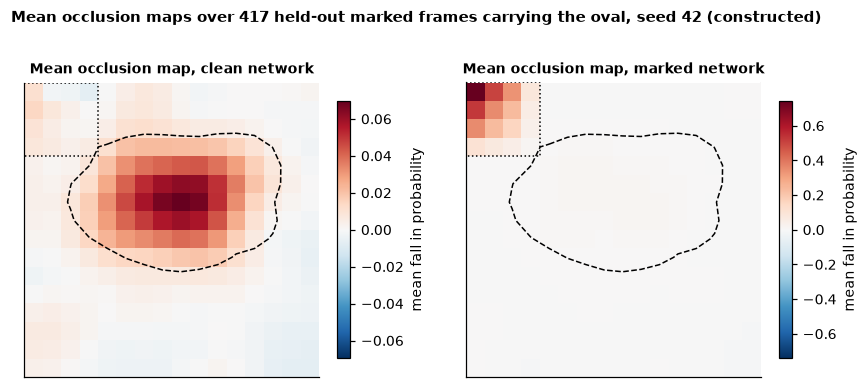

Each panel has its own colour scale. Dashed outline: pixels inside the oval in at least one frame in ten. Dotted square: the corner.
Share of the map's positive part in the corner: clean network 0.052, marked network 0.816; on the oval's own pixels: 0.383 and 0.056 (seed 42).
Corner share, marked network less clean network, on 20 further seeds: higher: the difference runs from +0.711 to +0.884 across 20 seeds. Oval share: lower: the difference runs from -0.424 to -0.315 across 20 seeds.
A map shows where the network looked, not why, and can look the same for two different labels (E-118).


In [16]:
run = cn.image_run()
pick = ~run.train & run.images.oval & run.marked.marked
fill = run.marked.background()[pick]
mean_maps = [cn.occlusion_maps(model, run.marked.pixels[pick], fill).mean(axis=0) for model in (run.clean, run.shortcut)]
where = run.images.mask[pick].mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, mm, name in zip(axes, mean_maps, ("clean network", "marked network")):
    top = np.abs(mm).max()
    image = ax.imshow(mm, cmap="RdBu_r", vmin=-top, vmax=top)
    ax.add_patch(plt.Rectangle((-0.5, -0.5), cn.CORNER, cn.CORNER, fill=False, edgecolor="black", linestyle=":"))
    ax.contour(where, levels=[0.1], colors=["black"], linewidths=1.0, linestyles="--")
    ax.set_title(f"Mean occlusion map, {name}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(image, ax=ax, shrink=0.8, label="mean fall in probability")
fig.suptitle(f"Mean occlusion maps over {int(pick.sum())} held-out marked frames carrying the oval, seed {cn.SEED} "
             "(constructed)", fontsize=10, fontweight="bold", y=1.02)
plt.show()
print("Each panel has its own colour scale. Dashed outline: pixels inside the oval in at least one frame in ten. "
      "Dotted square: the corner.")
print(f"Share of the map's positive part in the corner: clean network {m['corner share: clean network']:.3f}, marked "
      f"network {m['corner share: shortcut network']:.3f}; on the oval's own pixels: {m['oval share: clean network']:.3f} "
      f"and {m['oval share: shortcut network']:.3f} (seed {cn.SEED}).")
print(f"Corner share, marked network less clean network, on {len(sp)} further seeds: "
      f"{cn.image_words('corner share: shortcut network', 'corner share: clean network')}. Oval share: "
      f"{cn.image_words('oval share: shortcut network', 'oval share: clean network')}.")
print(cn.MAP_CAUTION)

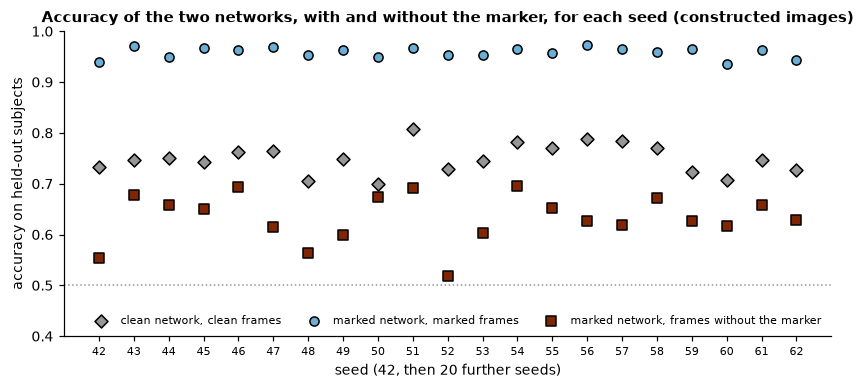

In [17]:
acc = pd.DataFrame({"clean network, clean frames": [m["accuracy: by subject"], *sp["accuracy: by subject"]],
                    "marked network, marked frames": [m["accuracy: marker, marked frames"],
                                                      *sp["accuracy: marker, marked frames"]],
                    "marked network, frames without the marker": [m["accuracy: marker, clean frames"],
                                                                  *sp["accuracy: marker, clean frames"]]},
                   index=[cn.SEED, *sp.index])
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(acc))
for col, colour, mark in zip(acc.columns, (GREY, PALE, DARK), ("D", "o", "s")):
    ax.scatter(x, acc[col], color=colour, edgecolor="black", marker=mark, zorder=3, label=col)
ax.axhline(0.5, color=GREY, linestyle=":", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels([str(s) for s in acc.index], fontsize=7)
ax.set_xlabel("seed (42, then 20 further seeds)")
ax.set_ylabel("accuracy on held-out subjects")
ax.set_ylim(0.4, 1.0)
ax.set_title("Accuracy of the two networks, with and without the marker, for each seed (constructed images)")
ax.legend(frameon=False, fontsize=7, loc="lower right", ncol=3)
plt.show()

This is the answer to the hook. In E-98, pneumonia prevalence was 34.2% at one site and 1.2% at another, and a network could tell which hospital a film came from for 99.95% and 99.98% of images. Ranking films by hospital alone scored an area under the curve of 0.861; the jointly trained model scored 0.931 on internal data and 0.815 at a third site (E-98). The hospital went with the label, and the film gave away the hospital, as the corner marker goes with the oval here. In E-100, chest radiograph models that looked accurate relied on confounding features, not lung pathology, and failed in new hospitals (E-100).

The military literature has met the same problem. In E-103, models trained on scans from five military working dogs and a cadaver model all exceeded 82% accuracy, one reaching 99.8% at the bladder view, and heat maps showed that the most accurate models did not always attend to the relevant features (E-103). The maps here and in E-103 show where a network looked. They do not show why: a map shows where the network looked, not why, and can look the same for two different labels (E-118). A map that falls on the oval is reassuring; it is not proof that the network has learned what the oval means.

### A second failure: a site it never saw

The network trained on clean frames of sites A and B is now scored on 1,600 frames of 200 subjects from site C, which it never saw. Site C's frames are a little darker and its ovals sit lower in the frame, as if the machine were set differently; both are assumptions.

Seed 42: area under the curve 0.573 on 1,600 frames of site C, against 0.802 on every frame of held-out subjects of A and B; accuracy 54.7% against 73.4% (constructed images).
Unseen less held-out, on 20 further seeds: lower: the difference runs from -0.339 to -0.161 across 20 seeds in area under the curve.


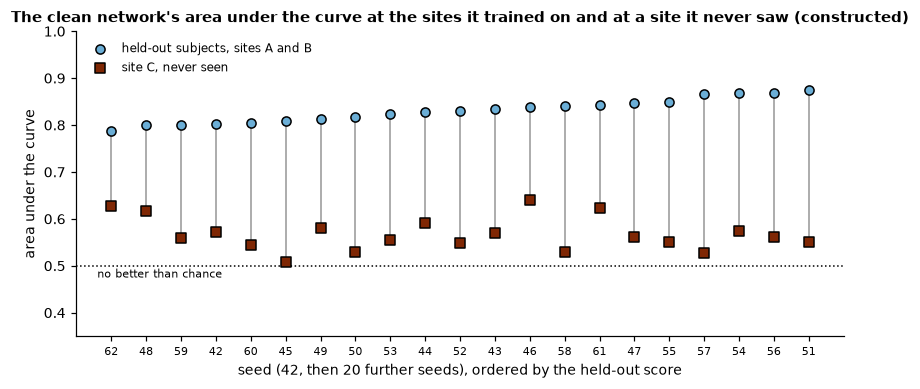

E-48, as published: the winning sepsis entry scored 0.360 overall, 0.433 and 0.434 on the two hospital systems it had seen, and -0.123 on the one it had not (E-48).


In [18]:
print(f"Seed {cn.SEED}: area under the curve {m['auc: unseen site']:.3f} on {m['unseen frames']:,} frames of site C, "
      f"against {m['auc: by subject']:.3f} on every frame of held-out subjects of A and B; accuracy "
      f"{m['accuracy: unseen site']:.1%} against {m['accuracy: by subject']:.1%} (constructed images).")
print(f"Unseen less held-out, on {len(sp)} further seeds: {cn.image_words('auc: unseen site', 'auc: by subject')} "
      f"in area under the curve.")
site = pd.DataFrame({"held-out subjects, sites A and B": [m["auc: by subject"], *sp["auc: by subject"]],
                     "site C, never seen": [m["auc: unseen site"], *sp["auc: unseen site"]]},
                    index=[cn.SEED, *sp.index]).sort_values("held-out subjects, sites A and B")
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(site))
ax.vlines(x, site.iloc[:, 1], site.iloc[:, 0], color=GREY, linewidth=1)
for col, colour, mark in zip(site.columns, (PALE, DARK), ("o", "s")):
    ax.scatter(x, site[col], color=colour, edgecolor="black", marker=mark, zorder=3, label=col)
ax.axhline(0.5, color="black", linestyle=":", linewidth=1)
ax.text(-0.4, 0.475, "no better than chance", ha="left", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels([str(s) for s in site.index], fontsize=7)
ax.set_xlabel("seed (42, then 20 further seeds), ordered by the held-out score")
ax.set_ylabel("area under the curve")
ax.set_ylim(0.35, 1.0)
ax.set_title("The clean network's area under the curve at the sites it trained on and at a site it never saw (constructed)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()
print(f"E-48, as published: the winning sepsis entry scored {cn.E48['overall']:.3f} overall, {cn.E48['seen'][0]} and "
      f"{cn.E48['seen'][1]} on the two hospital systems it had seen, and {cn.E48['unseen']} on the one it had not (E-48).")

The network does worse at the unseen site on every seed, and on some it is little better than chance. A network given pixels has no built-in notion that an oval lower in the frame is the same oval: it learned the rows it was shown. That explanation is the notebook's own reading of the fall, and is not a finding of any source.

E-48 is the same failure in a table of numbers rather than an image. In the PhysioNet 2019 challenge, over 60,000 intensive care patients from three hospital systems, records from two systems were shared and records from all three held back. The winning entry's utility score was 0.433 and 0.434 on the two systems it had seen and fell below zero, to -0.123, on the one it had not (E-48). The score rewards prediction from 6 hours before onset and penalises late and false alerts (E-48). Like the network at site C, it was scored where it had not been trained, and did worse there.

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed and carry the **mechanism** label; axes 3, 4 and 5 are stated; axis 7 is net benefit at a threshold of 0.10 for every lens (D-26). Net benefit judges a model by its consequences, at a threshold probability that encodes how a false alarm is weighed against a miss (E-93); here it is computed per 100 casualties as those correctly flagged less those wrongly flagged, the second weighted by the threshold over one minus it, and set beside flagging every casualty and flagging none, which scores zero.

The diagnosis column is the image network on constructed images: no baseline reads an image, and the MPTT-24 columns belong to the treatment column, the network on the signs. The baseline is the MPTT-24 under the figure reading, as published, with the text reading beside it, labelled as validated (D-24). For the image network the care setting does not apply, so axis 6 changes the site instead.

In [19]:
display(cn.seven_axes())

,diagnosis: image network (constructed images),treatment: network on the signs (weak fit),"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)"
axis,,,,
1 Discrimination (mechanism),"Area under the curve 0.802, sensitivity 78.5%, specificity 67.6% at 0.5, on 800 frames of 100 held-out subjects of sites A and B (constructed images, seed 42). With frames split at random instead, 0.929; by frame less by subject, on 20 further seeds (43 onward), is higher: the difference runs from +0.051 to +0.142 across 20 seeds. Sensitivity on small ovals 67.3% (248 frames), on large 94.3% (176 frames); large less small is higher: the difference runs from +0.161 to +0.482 across 20 seeds (E-99)","sensitivity 69.3% and specificity 78.6% at its own threshold, area under the curve 0.8197, on 100,000 synthetic casualties, every stream; among battle casualties alone, sensitivity 73.0% and specificity 65.7% at its own threshold, area under the curve 0.7605. Area under the curve less logistic score (lens 02)'s: on every stream, higher: the difference runs from +0.0046 to +0.0060 across 20 seeds; among battle casualties alone, higher: the difference runs from +0.0054 to +0.0078 across 20 seeds; less single tree (lens 04)'s: on every stream, higher: the difference runs from +0.0520 to +0.0570 across 20 seeds; among battle casualties alone, higher: the difference runs from +0.0493 to +0.0573 across 20 seeds; less forest (lens 04)'s: on every stream, higher: the difference runs from +0.0035 to +0.0049 across 20 seeds; among battle casualties alone, higher: the difference runs from +0.0021 to +0.0044 across 20 seeds. Sensitivity less MPTT-24, figure (as published)'s: on every stream, higher: the difference runs from +0.086 to +0.101 across 20 seeds; among battle casualties alone, higher: the difference runs from +0.099 to +0.113 across 20 seeds. Specificity less MPTT-24, figure (as published)'s: on every stream, a tie: no detectable difference (the difference runs from -0.003 to +0.003 across 20 seeds); among battle casualties alone, lower: the difference runs from -0.085 to -0.071 across 20 seeds","sensitivity 60.0% and specificity 78.6% on every stream; among battle casualties alone, sensitivity 62.7% and specificity 73.9%. The scorecard's figures are on every stream of the military cohort, disease included, and among battle casualties alone. On every stream of the military cohort, 16.7% of casualties need a life-saving intervention. Of the battle casualties alone, 50.2% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so they are not a milder cohort than the one the rule was validated on; of the injured as a whole, battle and non-battle, 26.5% need one, so the generator's injured are a milder cohort (D-23). The generator's signs are assumptions, tuned until the rule landed within 0.05 of E-09's accuracy, which was measured on first recorded hospital respiratory rate and registry GCS, not at the point of injury.","sensitivity 61.4% and specificity 77.8% on every stream; among battle casualties alone, sensitivity 64.1% and specificity 73.1%"
2 Calibration (mechanism),"Brier 0.207, where lower is better, from 0.145 to 0.219 across 20 further seeds; mean probability minus share with the oval +0.044, from -0.147 to +0.093 across 20 further seeds. No baseline reads an image","Brier 0.1080, where lower is better; mean probability minus share in need +0.0029 on every stream, -0.2190 among battle casualties alone: it does not read the stream and was fitted on every stream, so among battle casualties, where more are in need, it runs low. Brier score less logistic score (lens 02)'s: on every stream, lower, so better: the difference runs from -0.0019 to -0.0014 across 20 seeds; among battle casualties alone, lower, so better: the difference runs from -0.0094 to -0.0082 across 20 seeds; less forest (lens 04)'s: on every stream, lower, so better: the difference runs from -0.0007 to -0.0004 across 2

In [20]:
card = pd.DataFrame([vars(row) for row in cn.LENS.scorecard()])
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, image network against the oval, constructed images, held-out subjects, seed 42",0.7854,NaN,mechanism,native,constructed images
1,diagnosis,"specificity, image network against the oval, constructed images, held-out subjects, seed 42",0.6755,NaN,mechanism,native,constructed images
2,diagnosis,"Brier score, where lower is better, image network against the oval, constructed images, held-out subjects, seed 42",0.2066,NaN,mechanism,native,constructed images
3,diagnosis,"mean probability minus share with the oval, image network against the oval, constructed images, held-out subjects, seed 42",0.0443,NaN,mechanism,native,constructed images
4,treatment,"sensitivity, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.6925,0.5999,mechanism,weak,generator
5,treatment,"specificity, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.7865,0.7856,mechanism,weak,generator
6,treatment,"Brier score, where lower is better, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.1080,0.2454,mechanism,weak,generator
7,treatment,"mean probability minus share in need, network on the signs against need for a life-saving intervention, every stream, scan before hospital",0.0029,0.1118,mechanism,weak,generator
8,treatment,"sensitivity, network on the signs against need for a life-saving intervention, every stream, scan in hospital",0.6925,0.5999,mechanism,weak,generator
9,treatment,"specificity, network on the signs against need for a life-saving intervention, every stream, scan in hospital",0.7865,0.7856,mechanism,weak,generator


Two rows carry the lesson.

**Diagnosis.** On constructed images, the image network's score depends on how its frames were split, on whether a shortcut was there to take, and on whether it is scored where it was trained. Each of the three moves the score the same way on every one of the 20 further seeds. None of them would show in a held-out set drawn the same way as the training set.

**Treatment.** On four bedside signs, the network beats lens 02's score and lens 04's forest on every sample, by a fraction of a point, and among battle casualties alone its net benefit ties with the forest's and falls below flagging every casualty's on every sample, as every model's does there on seed 42. A network finds its own features; here there were few left to find.

## The brain analogy, and where it breaks

**What it resembles.** Layered cortex: a stack of stages, each working on what the stage before it made; the name *neural network* comes from the resemblance. Training by backpropagation passes an error signal back through the layers. Backpropagation was long thought implausible in the brain; E-58 argues that feedback may instead induce differences in activity that approximate error signals locally (E-58).

**Where it breaks.** Backpropagation has no agreed biological form. E-58 is a hypothesis about how the brain might approximate it, not evidence that it does. And the failure in this notebook is not one the analogy explains: a network takes whatever in its examples goes with the label, and nothing in its training asks whether that is the right thing. The child in the opening, told that the dog on the lawn was a cat, could be asked what she was looking at. The network can only be tested, or have its map read, and a map shows where the network looked, not why, and can look the same for two different labels (E-118).